# Laboratorio 2 · Predicción de aprobación con un perceptrón multicapa

**Contexto.** En analítica académica interesa detectar a tiempo si un estudiante aprobará
una asignatura para diseñar estrategias de apoyo. Este notebook construye y evalúa un
perceptrón multicapa (MLP) que predice `Aprobado` a partir del rendimiento académico y de
los hábitos del estudiante.

**Objetivos**

1. Verificar el balance de clases y la calidad del dataset.
2. Imputar valores ausentes con la mediana de cada columna.
3. Estandarizar las características (media 0, varianza 1).
4. Entrenar un MLP y optimizar sus capas ocultas con validación cruzada.
5. Evaluar sobre un conjunto de prueba independiente con matriz de confusión,
   precision, recall, F1, accuracy y ROC-AUC.
6. Analizar qué variables aportan y extraer conclusiones.

**Cómo ejecutar.** Desde la carpeta del proyecto:

```bash
pip install jupyterlab
jupyter lab MLP_estudiantes.ipynb
```

El notebook reproduce el pipeline de `scripts/entrenar_modelo.py` y sirve como
evidencia del proceso. La aplicación web está en `app.py`.

In [1]:
from pathlib import Path
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

%matplotlib inline

pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})

SEMILLA = 42
CARACTERISTICAS = [
    "Tareas",
    "Examenes",
    "Asistencia",
    "Estudio_Horas",
    "Sueno_Horas",
    "Extracurriculares",
]
OBJETIVO = "Aprobado"
ETIQUETAS = ["Reprobado", "Aprobado"]

RAIZ = Path.cwd()
RUTA_DATOS = RAIZ / "dataset_estudiantes_balanceado.csv"
if not RUTA_DATOS.exists():
    RUTA_DATOS = RAIZ.parent / "dataset_estudiantes_balanceado.csv"

print(f"scikit-learn {sklearn.__version__} | pandas {pd.__version__} | numpy {np.__version__}")
print(f"Dataset: {RUTA_DATOS.name}")

scikit-learn 1.9.1 | pandas 3.1.0 | numpy 2.5.4
Dataset: dataset_estudiantes_balanceado.csv

## 1. Carga de datos

El archivo contiene 600 registros con variables académicas (`Tareas`, `Examenes`,
`Asistencia`), hábitos (`Estudio_Horas`, `Sueno_Horas`, `Extracurriculares`) y dos salidas:
`Calificacion_Final` y `Aprobado`.

In [2]:
df = pd.read_csv(RUTA_DATOS)
print(f"Filas: {df.shape[0]} | Columnas: {df.shape[1]}")
display(df.head())
display(df.dtypes.to_frame("tipo"))

Filas: 600 | Columnas: 8


,Tareas,Examenes,Asistencia,Estudio_Horas,Sueno_Horas,Extracurriculares,Calificacion_Final,Aprobado
0,56.218,33.515,85.496,24.000,5.703,1,79.672,1
1,96.550,42.287,41.475,18.963,4.359,1,82.651,1
2,81.240,34.161,41.327,10.125,6.048,0,60.380,0
3,71.906,27.096,59.417,13.791,5.556,1,63.817,0
4,40.921,29.651,69.806,10.043,7.386,0,49.875,0


,tipo
Tareas,float64
Examenes,float64
Asistencia,float64
Estudio_Horas,float64
Sueno_Horas,float64
Extracurriculares,int64
Calificacion_Final,float64
Aprobado,int64


## 2. Calidad de los datos y balance de clases

Antes de modelar se revisan valores ausentes, duplicados y la proporción de la variable
objetivo. El taller exige un dataset balanceado 50/50 para evitar sesgos de clasificación.

In [3]:
nulos = df.isna().sum()
tabla_nulos = pd.DataFrame(
    {
        "valores_ausentes": nulos,
        "porcentaje": (nulos / len(df) * 100).round(2),
    }
)
display(tabla_nulos)
print(f"Duplicados exactos: {df.duplicated().sum()}")

conteos = df[OBJETIVO].value_counts().sort_index()
tabla_balance = pd.DataFrame(
    {
        "clase": ["Reprobado", "Aprobado"],
        "estudiantes": [int(conteos.get(0, 0)), int(conteos.get(1, 0))],
    }
)
tabla_balance["porcentaje"] = (tabla_balance["estudiantes"] / len(df) * 100).round(1)
display(tabla_balance)

,valores_ausentes,porcentaje
Tareas,0,0.0
Examenes,0,0.0
Asistencia,0,0.0
Estudio_Horas,0,0.0
Sueno_Horas,0,0.0
Extracurriculares,0,0.0
Calificacion_Final,0,0.0
Aprobado,0,0.0


Duplicados exactos: 0


,clase,estudiantes,porcentaje
0,Reprobado,300,50.0
1,Aprobado,300,50.0


**Lectura.** El dataset no tiene valores ausentes ni duplicados, y las clases están
exactamente balanceadas (300 y 300). Aun así, el pipeline incorporará una imputación por
mediana para que el modelo tolere datos incompletos en producción.

In [4]:
resumen = df[CARACTERISTICAS + ["Calificacion_Final"]].describe().T
resumen["mediana"] = df[CARACTERISTICAS + ["Calificacion_Final"]].median()
display(resumen[["count", "mean", "std", "min", "mediana", "max"]].round(3))

,count,mean,std,min,mediana,max
Tareas,600.0,65.034,20.436,30.354,65.988,99.980
Examenes,600.0,59.623,23.277,20.371,60.025,99.835
Asistencia,600.0,69.613,17.139,40.296,69.806,99.965
Estudio_Horas,600.0,13.515,6.499,2.036,13.791,24.962
Sueno_Horas,600.0,6.524,1.468,4.000,6.491,8.989
Extracurriculares,600.0,0.407,0.492,0.000,0.000,1.000
Calificacion_Final,600.0,74.669,14.506,37.548,74.674,110.833


## 3. Análisis exploratorio

Se revisa el balance, la distribución de cada variable por clase y la correlación con el
objetivo.

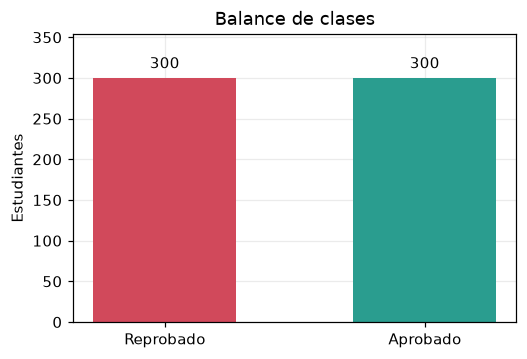

In [5]:
colores = {0: "#d1495b", 1: "#2a9d8f"}
fig, ax = plt.subplots(figsize=(5.2, 3.4))
barras = ax.bar(
    ["Reprobado", "Aprobado"],
    [int(conteos.get(0, 0)), int(conteos.get(1, 0))],
    color=[colores[0], colores[1]],
    width=0.55,
)
ax.bar_label(barras, fmt="%d", padding=4)
ax.set_title("Balance de clases")
ax.set_ylabel("Estudiantes")
ax.set_ylim(0, max(conteos) * 1.18)
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
plt.show()

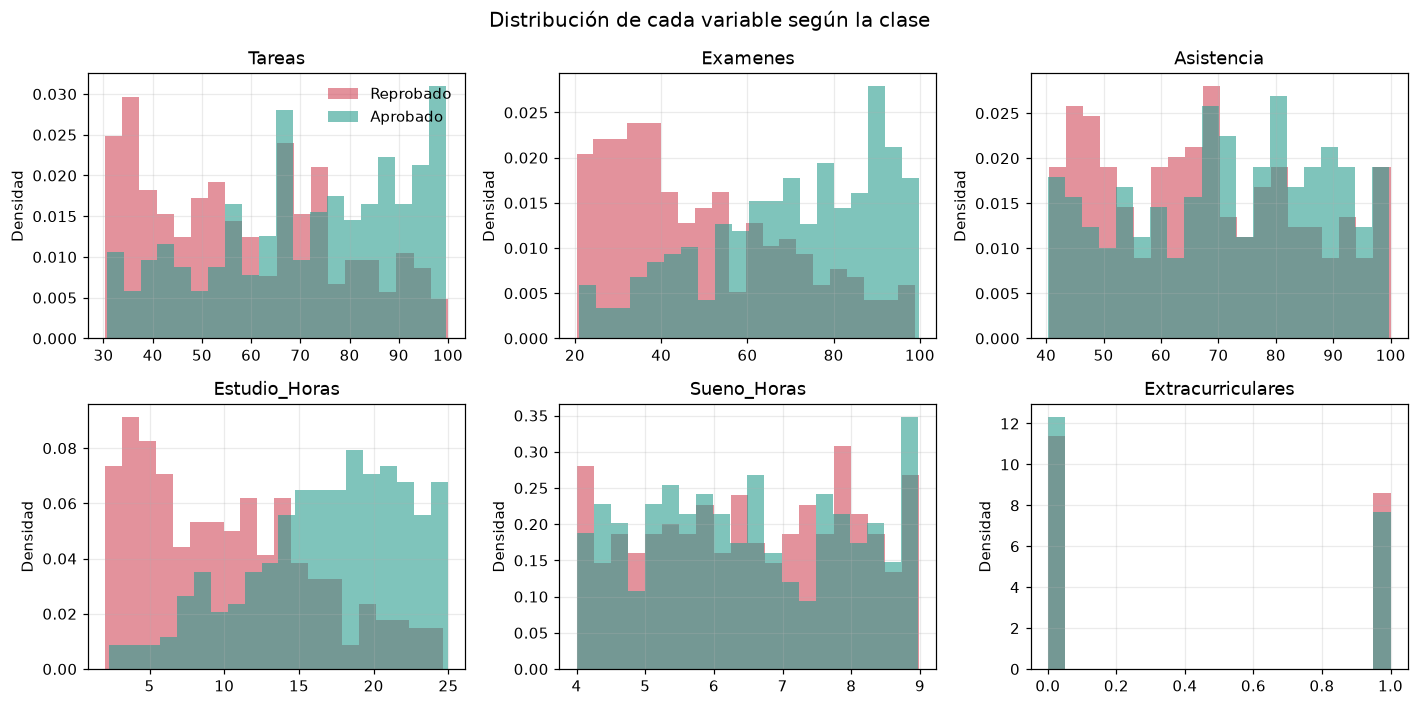

In [6]:
fig, ejes = plt.subplots(2, 3, figsize=(13, 6.5))
for eje, columna in zip(ejes.ravel(), CARACTERISTICAS):
    for clase in (0, 1):
        datos = df.loc[df[OBJETIVO] == clase, columna]
        eje.hist(
            datos,
            bins=20,
            alpha=0.6,
            color=colores[clase],
            label=ETIQUETAS[clase],
            density=True,
        )
    eje.set_title(columna)
    eje.set_ylabel("Densidad")
ejes[0, 0].legend(frameon=False)
fig.suptitle("Distribución de cada variable según la clase", fontsize=13)
fig.tight_layout()
plt.show()

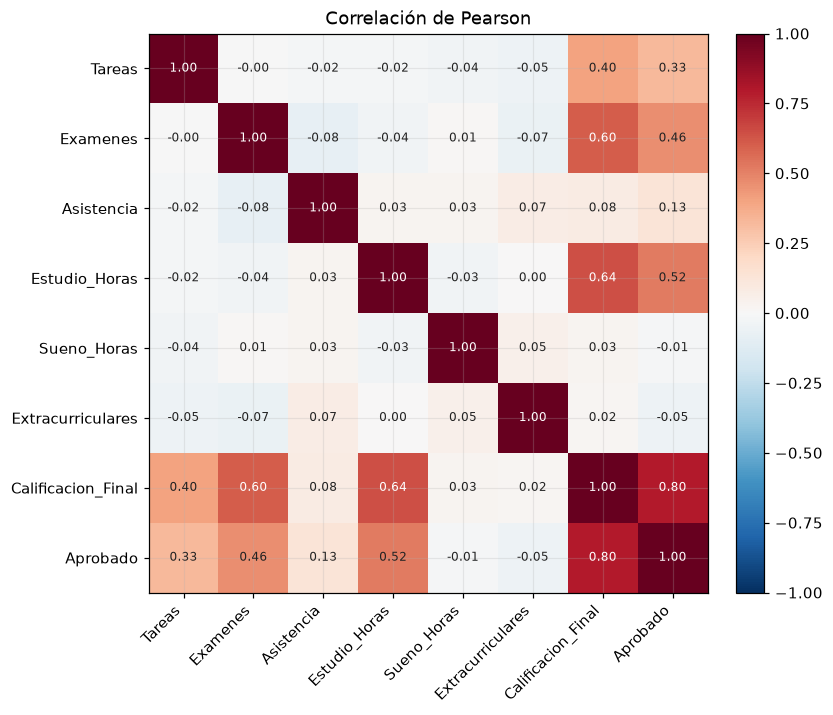

,correlación con Aprobado
Calificacion_Final,0.795
Estudio_Horas,0.520
Examenes,0.462
Tareas,0.326
Asistencia,0.130
Extracurriculares,-0.048
Sueno_Horas,-0.012


In [7]:
columnas_corr = CARACTERISTICAS + ["Calificacion_Final", OBJETIVO]
correlacion = df[columnas_corr].corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(8.4, 6.6))
imagen = ax.imshow(correlacion, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(columnas_corr)), columnas_corr, rotation=45, ha="right")
ax.set_yticks(range(len(columnas_corr)), columnas_corr)
for i in range(len(columnas_corr)):
    for j in range(len(columnas_corr)):
        ax.text(
            j,
            i,
            f"{correlacion.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=8,
            color="white" if abs(correlacion.iloc[i, j]) > 0.55 else "#222222",
        )
ax.set_title("Correlación de Pearson")
fig.colorbar(imagen, ax=ax, fraction=0.046, pad=0.04)
plt.show()

display(
    correlacion[OBJETIVO]
    .drop(OBJETIVO)
    .sort_values(key=np.abs, ascending=False)
    .round(3)
    .to_frame("correlación con Aprobado")
)

**Lectura.**

- Las variables académicas y las horas de estudio son las que más se separan entre clases.
- `Sueno_Horas` y `Extracurriculares` tienen correlaciones cercanas a cero y distribuciones
  muy superpuestas: aportan poca señal.
- `Calificacion_Final` es una **salida** del dataset y `Aprobado` se deriva de ella.
  Usarla como entrada produciría fuga de información, por eso se excluye del modelo.

## 4. Imputación, estandarización y división de los datos

Primero se separa el 20 % de los registros como set de prueba independiente. Todas las
transformaciones se ajustan **solo con el set de entrenamiento** para evitar fuga de
información, y luego se aplican al set de prueba.

In [8]:
X = df[CARACTERISTICAS].copy()
y = df[OBJETIVO].astype(int)

X_entrenamiento, X_prueba, y_entrenamiento, y_prueba = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=SEMILLA,
)

print(f"Entrenamiento: {len(X_entrenamiento)} registros")
print(f"Prueba: {len(X_prueba)} registros")
print("Distribución en entrenamiento:")
print(y_entrenamiento.value_counts().rename(index={0: "Reprobado", 1: "Aprobado"}))

medianas = X_entrenamiento.median()
display(medianas.round(2).to_frame("mediana usada para imputar").T)

Entrenamiento: 480 registros
Prueba: 120 registros
Distribución en entrenamiento:
Aprobado
Reprobado    240
Aprobado     240
Name: count, dtype: int64


,Tareas,Examenes,Asistencia,Estudio_Horas,Sueno_Horas,Extracurriculares
mediana usada para imputar,65.99,60.25,69.81,13.79,6.43,0.0


In [9]:
imputador = SimpleImputer(strategy="median").fit(X_entrenamiento)
X_entrenamiento_imputado = pd.DataFrame(
    imputador.transform(X_entrenamiento), columns=CARACTERISTICAS
)

escalador = StandardScaler().fit(X_entrenamiento_imputado)
X_entrenamiento_escalado = pd.DataFrame(
    escalador.transform(X_entrenamiento_imputado), columns=CARACTERISTICAS
)

verificacion = pd.DataFrame(
    {
        "media (train)": X_entrenamiento_escalado.mean(),
        "desviación (train)": X_entrenamiento_escalado.std(ddof=1),
        "mínimo": X_entrenamiento_escalado.min(),
        "máximo": X_entrenamiento_escalado.max(),
    }
)
display(verificacion.round(3))

,media (train),desviación (train),mínimo,máximo
Tareas,0.0,1.001,-1.726,1.746
Examenes,0.0,1.001,-1.696,1.742
Asistencia,0.0,1.001,-1.739,1.792
Estudio_Horas,-0.0,1.001,-1.772,1.767
Sueno_Horas,-0.0,1.001,-1.703,1.683
Extracurriculares,0.0,1.001,-0.831,1.204


La estandarización deja cada característica con media 0 y desviación estándar 1. En el
modelo final estas transformaciones van dentro de un `Pipeline`, de modo que la validación
cruzada las reajusta en cada fold y no hay contaminación entre entrenamiento y prueba.

## 5. Diseño y entrenamiento del MLP

Se prueban distintas arquitecturas de capas ocultas y valores de regularización con
`GridSearchCV` (5 folds, métrica F1). La red usa activación ReLU, optimizador Adam y
*early stopping* para detener el entrenamiento cuando la validación interna deja de mejorar.

In [10]:
pipeline = Pipeline(
    steps=[
        ("imputador", SimpleImputer(strategy="median")),
        ("escalador", StandardScaler()),
        (
            "mlp",
            MLPClassifier(
                solver="adam",
                activation="relu",
                max_iter=1500,
                early_stopping=True,
                n_iter_no_change=30,
                validation_fraction=0.15,
                random_state=SEMILLA,
            ),
        ),
    ]
)

rejilla = {
    "mlp__hidden_layer_sizes": [(16,), (32,), (32, 16), (64, 32)],
    "mlp__alpha": [1e-4, 1e-3, 1e-2],
    "mlp__learning_rate_init": [0.001, 0.01],
}

validacion = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
busqueda = GridSearchCV(
    estimator=pipeline,
    param_grid=rejilla,
    scoring="f1",
    cv=validacion,
    n_jobs=1,
    refit=True,
)

inicio = time.perf_counter()
busqueda.fit(X_entrenamiento, y_entrenamiento)
duracion = time.perf_counter() - inicio

print(f"Búsqueda completada en {duracion:.1f} s")
print(f"Combinaciones evaluadas: {len(busqueda.cv_results_['params'])}")
print(f"Mejor F1 medio en validación cruzada: {busqueda.best_score_:.4f}")
print("Mejores hiperparámetros:")
for clave, valor in busqueda.best_params_.items():
    print(f"  - {clave}: {valor}")

modelo = busqueda.best_estimator_

Búsqueda completada en 79.0 s
Combinaciones evaluadas: 24
Mejor F1 medio en validación cruzada: 0.9857
Mejores hiperparámetros:
  - mlp__alpha: 0.001
  - mlp__hidden_layer_sizes: (32, 16)
  - mlp__learning_rate_init: 0.01


Arquitectura: 6 -> (32, 16) -> 1
Épocas entrenadas: 43
Función de activación: relu | optimizador: adam


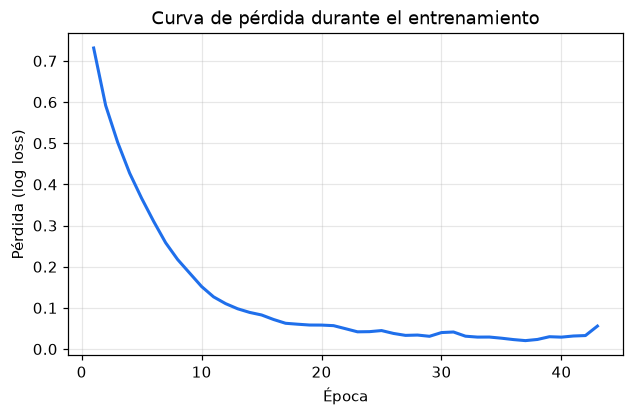

In [11]:
mlp = modelo.named_steps["mlp"]
print(f"Arquitectura: 6 -> {mlp.hidden_layer_sizes} -> 1")
print(f"Épocas entrenadas: {mlp.n_iter_}")
print(f"Función de activación: {mlp.activation} | optimizador: {mlp.solver}")

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(range(1, len(mlp.loss_curve_) + 1), mlp.loss_curve_, color="#1f6feb", linewidth=2)
ax.set_title("Curva de pérdida durante el entrenamiento")
ax.set_xlabel("Época")
ax.set_ylabel("Pérdida (log loss)")
ax.grid(alpha=0.3)
plt.show()

## 6. Evaluación sobre el set de prueba

El set de prueba no participó en el entrenamiento ni en la búsqueda de hiperparámetros.
Se reportan las métricas solicitadas y la matriz de confusión.

In [12]:
y_pred = modelo.predict(X_prueba)
y_prob = modelo.predict_proba(X_prueba)[:, 1]

metricas = {
    "Accuracy": accuracy_score(y_prueba, y_pred),
    "Precision": precision_score(y_prueba, y_pred),
    "Recall": recall_score(y_prueba, y_pred),
    "F1-Score": f1_score(y_prueba, y_pred),
    "ROC-AUC": roc_auc_score(y_prueba, y_prob),
}

tabla_metricas = pd.DataFrame(
    {"métrica": list(metricas.keys()), "valor": [round(v, 4) for v in metricas.values()]}
)
display(tabla_metricas)

print(classification_report(y_prueba, y_pred, target_names=ETIQUETAS, digits=4))

,métrica,valor
0,Accuracy,0.967
1,Precision,0.983
2,Recall,0.950
3,F1-Score,0.966
4,ROC-AUC,0.997


              precision    recall  f1-score   support

   Reprobado     0.9516    0.9833    0.9672        60
    Aprobado     0.9828    0.9500    0.9661        60

    accuracy                         0.9667       120
   macro avg     0.9672    0.9667    0.9667       120
weighted avg     0.9672    0.9667    0.9667       120



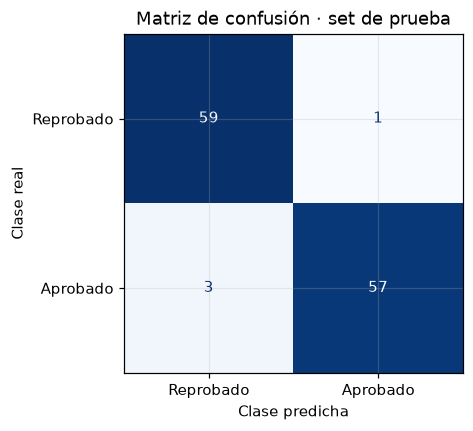

Predicho,Reprobado,Aprobado
Real,,
Reprobado,59,1
Aprobado,3,57


Verdaderos negativos: 59 | Falsos positivos: 1
Falsos negativos: 3 | Verdaderos positivos: 57


In [13]:
cm = confusion_matrix(y_prueba, y_pred, labels=[0, 1])

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(cm, display_labels=ETIQUETAS).plot(
    ax=ax, cmap="Blues", colorbar=False, values_format="d"
)
ax.set_title("Matriz de confusión · set de prueba")
ax.set_xlabel("Clase predicha")
ax.set_ylabel("Clase real")
plt.show()

tabla_cm = pd.DataFrame(
    cm,
    index=pd.Index(ETIQUETAS, name="Real"),
    columns=pd.Index(ETIQUETAS, name="Predicho"),
)
display(tabla_cm)
print(f"Verdaderos negativos: {cm[0, 0]} | Falsos positivos: {cm[0, 1]}")
print(f"Falsos negativos: {cm[1, 0]} | Verdaderos positivos: {cm[1, 1]}")

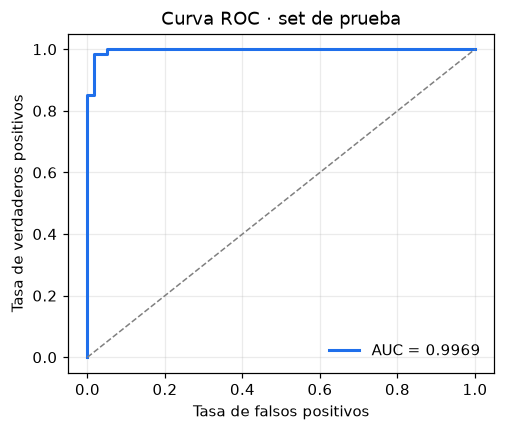

In [14]:
fpr, tpr, _ = roc_curve(y_prueba, y_prob)

fig, ax = plt.subplots(figsize=(5, 4))
ax.plot(fpr, tpr, color="#1f6feb", linewidth=2, label=f"AUC = {metricas['ROC-AUC']:.4f}")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", linewidth=1)
ax.set_title("Curva ROC · set de prueba")
ax.set_xlabel("Tasa de falsos positivos")
ax.set_ylabel("Tasa de verdaderos positivos")
ax.legend(frameon=False, loc="lower right")
plt.show()

**Lectura de la matriz.** De 120 estudiantes, el modelo clasifica correctamente 116:
59 reprobados y 57 aprobados. Comete 1 falso positivo (predice aprobado cuando reprobó) y
3 falsos negativos (predice reprobado cuando aprobó). El ROC-AUC cercano a 1 indica una
excelente separación entre clases.

## 7. ¿Qué variables aportan al modelo?

La importancia por permutación mide cuánto empeora el F1 cuando se desordena una variable
en el set de prueba. Si el valor es cercano a cero, el modelo no la necesita.

,variable,importancia media,desviación
3,Estudio_Horas,0.260,0.031
1,Examenes,0.236,0.033
0,Tareas,0.193,0.031
2,Asistencia,0.066,0.022
5,Extracurriculares,0.013,0.009
4,Sueno_Horas,0.004,0.012


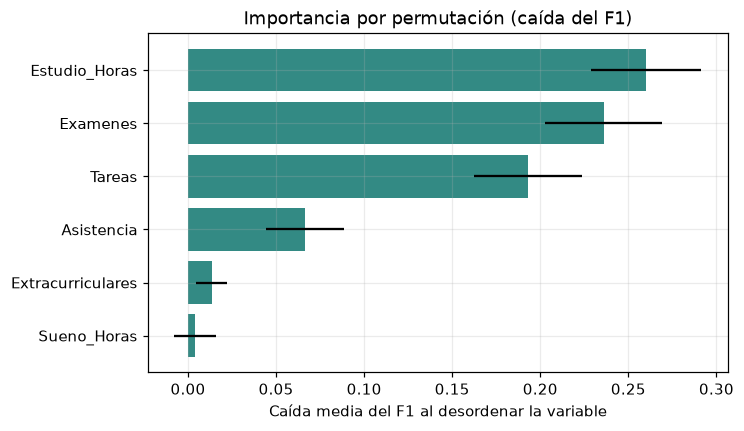

In [15]:
importancia = permutation_importance(
    modelo,
    X_prueba,
    y_prueba,
    scoring="f1",
    n_repeats=30,
    random_state=SEMILLA,
    n_jobs=1,
)

tabla_importancia = pd.DataFrame(
    {
        "variable": CARACTERISTICAS,
        "importancia media": importancia.importances_mean,
        "desviación": importancia.importances_std,
    }
).sort_values("importancia media", ascending=False)

display(tabla_importancia.round(4))

fig, ax = plt.subplots(figsize=(6.8, 4))
ax.barh(
    tabla_importancia["variable"][::-1],
    tabla_importancia["importancia media"][::-1],
    xerr=tabla_importancia["desviación"][::-1],
    color="#0f766e",
    alpha=0.85,
)
ax.set_title("Importancia por permutación (caída del F1)")
ax.set_xlabel("Caída media del F1 al desordenar la variable")
plt.show()

**Lectura.** Tareas, Exámenes y horas de estudio concentran la importancia. Asistencia
aporta menos, y `Sueno_Horas` y `Extracurriculares` quedan prácticamente en cero, en línea
con lo observado en el análisis exploratorio. Como las variables académicas están
correlacionadas entre sí, la importancia individual debe interpretarse con cautela: parte
de la señal puede repartirse entre variables relacionadas.

## 8. Conclusiones

1. **Balanceo.** El dataset ya cumple la proporción 50/50 (300 aprobados y 300 reprobados),
   por lo que no fue necesario submuestrear. El script de producción verifica esta condición
   y solo aplicaría un balanceo si hiciera falta.
2. **Preprocesamiento.** La imputación por mediana y la estandarización se ajustan dentro
   del pipeline y solo con el set de entrenamiento. Esto evita fuga de información y hace
   que el modelo tolere datos incompletos en producción.
3. **Rendimiento.** El MLP alcanza un accuracy de **0.9667** y un F1 de **0.9661** en el set
   de prueba, con un ROC-AUC de **0.9969**. La brecha frente al F1 de validación cruzada
   (**0.9857**) es pequeña, así que no se aprecia sobreajuste relevante.
4. **Errores.** La matriz de confusión muestra 4 errores sobre 120 casos, repartidos entre
   ambas clases (1 falso positivo y 3 falsos negativos). Precision y recall por clase son
   equilibrados, lo que confirma que el modelo no está sesgado hacia una clase.
5. **Variables.** La señal está en el rendimiento académico y las horas de estudio.
   `Sueno_Horas` y `Extracurriculares` no aportan capacidad predictiva.
6. **Naturaleza del problema.** `Calificacion_Final` es una combinación lineal de las
   entradas y `Aprobado` se deriva de ella, por lo que el problema es casi linealmente
   separable. Un MLP pequeño basta y un rendimiento cercano al 97 % es esperable, no un
   indicio de que el modelo generalice a datos reales.
7. **Limitaciones y uso responsable.** El dataset es sintético; un uso real requiere datos
   más ricos, validación temporal y revisión de sesgos. La predicción debe servir como
   apoyo pedagógico, nunca como decisión automática sobre un estudiante.

## 9. Reproducibilidad y despliegue

- `scripts/entrenar_modelo.py` reproduce este pipeline, guarda el modelo en
  `models/mlp_estudiantes.joblib` y genera los reportes de `reports/`.
- `scripts/analisis_exploratorio.py` genera el análisis exploratorio y sus figuras.
- `app.py` carga el modelo y expone la predicción en una aplicación Streamlit lista para
  desplegar en Streamlit Community Cloud.

Para reentrenar desde la terminal:

```bash
python scripts/entrenar_modelo.py
```